# BT4012 Fraud Analytics Group 14: Misclassification analysis

## Libraries

In [33]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

## Configuration

In [34]:
# Reads the saved predictions only (no retraining, nothing saved): run after model.ipynb, model_classical.ipynb
# and model_graphsmote.ipynb. Each ranking flags its top FLAG_SHARE of companies in each test year.
# TP = fraud caught, FN = fraud missed, FP = clean company flagged, TN = clean company not flagged.
# "Current rule" = model.ipynb's ranking, which puts every company that was a fraud last year first.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_DIR = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = ROOT / "results"

KEYS = ["nodeID", "Year"]
FLAG_SHARE = 0.05                                               # review budget: top 5% of companies per test year
BUDGETS = [0.01, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30, 0.50]       # budgets for the first-time budget curve
RESERVES = np.round(np.arange(0, FLAG_SHARE + 1e-9, 0.005), 3)  # share of companies reserved for last year's frauds
TOP_FEATURES = 15
SEED = 0

NAMES = {"ens_score": "MLP + RGCN", "mlp_score": "MLP (no graph)", "rgcn_score": "RGCN",
         "xgb": "XGBoost", "gsmote": "GraphSMOTE"}
COLORS = {"ens_score": "#1baf7a", "mlp_score": "#2a78d6", "rgcn_score": "#eb6834", "xgb": "#7a5af5",
          "gsmote": "#d6a02a", "ens_own_new": "#0d6b4a", "xgb_new": "#7a5af5", "gsmote_new": "#d6a02a",
          "ens_xgb_new": "#c0397b"}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1",
                     "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
                     "legend.frameon": False, "font.size": 9.5})

splits = pd.read_csv(DATA_DIR / "splits" / "temporal_splits.csv")
TEST_YEARS = sorted(int(y) for y in splits.loc[splits["role"] == "test", "Year"].unique())
labels = splits[KEYS + ["Label"]].drop_duplicates(KEYS).astype({"Year": int, "Label": int})
print("test years:", TEST_YEARS)

test years: [2019, 2020, 2021, 2022]


## Loading predictions

In [35]:
def has_columns(path, columns):
    return path.exists() and set(columns) <= set(pd.read_csv(path, nrows=0).columns)


# model.ipynb: score = model_score + 1 for last year's frauds (the current rule); model_score = continuation model
# for last year's frauds and first-time model for everyone else. GraphSMOTE's file of the same name lacks model_score.
candidates = [RESULTS_DIR / "rgcn_predictions.csv", RESULTS_DIR / "rgcn_baseline" / "rgcn_predictions.csv"]
rgcn_path = next((p for p in candidates if has_columns(p, ["network_score", "model_score"])), None)
if rgcn_path is None:
    raise FileNotFoundError("model.ipynb's rgcn_predictions.csv (with model_score and network_score) wasn't found.")
rgcn_preds = pd.read_csv(rgcn_path).astype({"Year": int, "Label": int})
wide = rgcn_preds.query("model == 'ens'")[KEYS + ["Label"]].reset_index(drop=True)
for m in ["ens", "mlp", "rgcn"]:
    rows = rgcn_preds.query("model == @m")[KEYS + ["score", "model_score"]]
    wide = wide.merge(rows.rename(columns={"score": f"{m}_score", "model_score": f"{m}_own"}), on=KEYS, how="left")
print(f"model.ipynb:            {rgcn_path.relative_to(ROOT)}")

# model_classical.ipynb: the file scores every split's rows; a test year first appears in its own split, so keep
# the first copy of each test-year row (the out-of-sample score) and check the AUCs
classical = pd.read_csv(RESULTS_DIR / "classical_predictions.csv").astype({"Year": int})
xgb = (classical[classical["model"] == "xgb"].drop_duplicates(KEYS, keep="first")
       .loc[lambda d: d["Year"].isin(TEST_YEARS), KEYS + ["Label", "score"]])
expected_auc = (pd.read_csv(RESULTS_DIR / "classical_results.csv")
                .query("model == 'xgb'").drop_duplicates("test_year").set_index("test_year")["test_auc"])
for year, rows in xgb.groupby("Year"):
    assert abs(roc_auc_score(rows["Label"], rows["score"]) - expected_auc[year]) < 1e-6, f"XGBoost AUC mismatch in {year}"
wide = wide.merge(xgb[KEYS + ["score"]].rename(columns={"score": "xgb"}), on=KEYS, how="left")
print(f"model_classical.ipynb:  {len(xgb):,} XGBoost test rows, AUCs match classical_results.csv")

# model_graphsmote.ipynb (optional)
gs_candidates = [RESULTS_DIR / "graphsmote" / "rgcn_predictions.csv", RESULTS_DIR / "graphsmote_predictions.csv",
                 RESULTS_DIR / "rgcn_predictions.csv"]
gs_path = next((p for p in gs_candidates
                if has_columns(p, ["model"]) and (pd.read_csv(p, usecols=["model"])["model"] == "gsmote").any()), None)
HAS_GSMOTE = gs_path is not None
if HAS_GSMOTE:
    gs = pd.read_csv(gs_path).query("model == 'gsmote'").astype({"Year": int})[KEYS + ["score"]]
    wide = wide.merge(gs.rename(columns={"score": "gsmote"}), on=KEYS, how="left")
    print(f"model_graphsmote.ipynb: {gs_path.relative_to(ROOT)}")
else:
    print("model_graphsmote.ipynb: not found, so GraphSMOTE is skipped")

score_cols = [c for c in wide.columns if c not in KEYS + ["Label"]]
assert wide[score_cols].notna().all().all(), "some company-years are missing a score: the files don't cover the same rows"

model.ipynb:            results\rgcn_predictions.csv
model_classical.ipynb:  17,985 XGBoost test rows, AUCs match classical_results.csv
model_graphsmote.ipynb: results\graphsmote\rgcn_predictions.csv


## Context for each company-year

In [36]:
last_year = labels.assign(Year=labels["Year"] + 1).rename(columns={"Label": "fraud_last_year"})
next_year = labels.assign(Year=labels["Year"] - 1).rename(columns={"Label": "fraud_next_year"})   # blank for 2022
degree = pd.read_csv(PROCESSED_DIR / "graph" / "degree_features.csv").astype({"Year": int})
DEGREE_COLS = [c for c in degree.columns if c not in KEYS]
text = pd.read_parquet(PROCESSED_DIR / "text_features.parquet")[KEYS + ["has_text"]].astype({"Year": int})

wide = (wide.merge(last_year, on=KEYS, how="left").merge(next_year, on=KEYS, how="left")
            .merge(degree, on=KEYS, how="left").merge(text, on=KEYS, how="left"))
wide["fraud_last_year"] = wide["fraud_last_year"].fillna(0).astype(int)
wide["connections"] = wide[DEGREE_COLS].fillna(0).sum(axis=1)   # edges across all relation types
# "repeat" = fraud last year. "first-time" = no fraud last year: mostly first frauds on record, but it also
# includes companies with a fraud two or more years earlier and companies with no row the year before.
wide["fraud_type"] = np.select([wide["Label"] == 0, wide["fraud_last_year"] == 1], ["clean", "repeat"], "first-time")

FRAUD = wide["Label"] == 1
FIRST_TIME = wide["fraud_type"] == "first-time"
REPEAT = wide["fraud_type"] == "repeat"
print(f"{len(wide):,} test company-years, {FRAUD.sum()} frauds ({FIRST_TIME.sum()} first-time, {REPEAT.sum()} repeat)")

17,985 test company-years, 727 frauds (204 first-time, 523 repeat)


## Helpers

In [37]:
def flag_top(column, share=FLAG_SHARE):
    """Flag the top `share` of companies in each test year by `column`."""
    rank = wide.groupby("Year")[column].rank(ascending=False, method="first")
    return rank <= np.ceil(share * wide.groupby("Year")[column].transform("size"))


def rank_pct(column):
    """Position in the year's ranking: 0.01 = top 1% of companies."""
    return wide.groupby("Year")[column].rank(ascending=False, method="first") / wide.groupby("Year")[column].transform("size")


def outcome(flags):
    return pd.Series(np.select([flags & FRAUD, flags & ~FRAUD, ~flags & FRAUD], ["TP", "FP", "FN"], "TN"), index=wide.index)


def summarise(flags):
    return {"frauds caught": int((flags & FRAUD).sum()),
            "first-time caught": int((flags & FIRST_TIME).sum()),
            "repeat caught": int((flags & REPEAT).sum()),
            "false positives": int((flags & ~FRAUD).sum()),
            "precision": round((flags & FRAUD).sum() / flags.sum(), 3)}


def split_budget(reserve, new_col, share=FLAG_SHARE):
    """Reserve `reserve` of companies for last year's frauds (ranked by MLP + RGCN), the rest for companies with no
    fraud last year (ranked by `new_col`). Reserving the whole budget reproduces the current rule."""
    flags = pd.Series(False, index=wide.index)
    for _, rows in wide.groupby("Year"):
        n_flag = int(np.ceil(share * len(rows)))
        repeat_rows = rows[rows["fraud_last_year"] == 1]
        n_repeat = min(int(np.ceil(reserve * len(rows))), len(repeat_rows), n_flag)   # unused reserve goes to new companies
        picked = repeat_rows.nlargest(n_repeat, "ens_own").index.union(
            rows[rows["fraud_last_year"] == 0].nlargest(n_flag - n_repeat, new_col).index)
        flags[picked] = True
    return flags


def grouped_bars(ax, table, cols, fmt="{:.0%}"):
    width = 0.8 / len(cols)
    x = np.arange(len(table.index))
    for i, c in enumerate(cols):
        bars = ax.bar(x + (i - (len(cols) - 1) / 2) * width, table[c], width, color=COLORS[c], label=NAMES[c])
        ax.bar_label(bars, labels=[fmt.format(v) for v in table[c]], fontsize=7.5, padding=2)
    ax.set_xticks(x, table.index)


MODELS = [c for c in NAMES if c in wide.columns]   # ens_score, mlp_score, rgcn_score, xgb, gsmote
FLAGS = {c: flag_top(c) for c in MODELS}           # each model's top 5%, ranked over all companies
wide["flagged"] = FLAGS["ens_score"]
wide["outcome"] = outcome(wide["flagged"])         # main model: MLP + RGCN, current rule

# Other rankings of the same saved scores
wide["history"] = wide["fraud_last_year"] + np.random.default_rng(SEED).random(len(wide))   # no model: last year's frauds first, rest random
by_year = wide.groupby("Year")
wide["ens_xgb"] = (by_year["ens_own"].rank(pct=True) + by_year["xgb"].rank(pct=True)) / 2   # average rank of the two models
NEW_ONLY = {"ens_own": "MLP + RGCN", "xgb": "XGBoost", "gsmote": "GraphSMOTE", "ens_xgb": "MLP + RGCN and XGBoost (average rank)"}
NEW_ONLY = {c: name for c, name in NEW_ONLY.items() if c in wide.columns}
for c in NEW_ONLY:   # whole budget for companies with no fraud last year (ens_own is then the first-time model's score)
    wide[f"{c}_new"] = wide[c].where(wide["fraud_last_year"] == 0, -np.inf)

## Overall results

### Outcomes at the top 5%

In [38]:
# MLP + RGCN TP and FP should match results/confusion_matrices.csv from model.ipynb
confusion = (pd.concat({NAMES[c]: outcome(f) for c, f in FLAGS.items()}, names=["model"])
             .rename("outcome").reset_index(level=0)
             .assign(Year=lambda d: wide.loc[d.index, "Year"].to_numpy())
             .groupby(["model", "Year", "outcome"]).size().unstack("outcome", fill_value=0)[["TP", "FP", "FN", "TN"]])
confusion["precision"] = (confusion["TP"] / (confusion["TP"] + confusion["FP"])).round(3)
confusion["recall"] = (confusion["TP"] / (confusion["TP"] + confusion["FN"])).round(3)
confusion.loc[[NAMES[c] for c in MODELS]]

outcome               TP   FP   FN    TN  precision  recall
model          Year                                        
MLP + RGCN     2019  144   47   70  3554      0.754   0.673
               2020  131   83   76  3979      0.612   0.633
               2021  137  102   46  4484      0.573   0.749
               2022  101  156   22  4853      0.393   0.821
MLP (no graph) 2019  139   52   75  3549      0.728   0.650
               2020  132   82   75  3980      0.617   0.638
               2021  138  101   45  4485      0.577   0.754
               2022  101  156   22  4853      0.393   0.821
RGCN           2019  144   47   70  3554      0.754   0.673
               2020  132   82   75  3980      0.617   0.638
               2021  137  102   46  4484      0.573   0.749
               2022  103  154   20  4855      0.401   0.837
XGBoost        2019   80  111  134  3490      0.419   0.374
               2020   87  127  120  3935      0.407   0.420
               2021   70  169  113  4417      0.293   0.383
               2022   60  197   63  4812      0.233   0.488
GraphSMOTE     2019   87  104  127  3497      0.455   0.407
               2020   67  147  140  3915      0.313   0.324
               2021   58  181  125  4405      0.243   0.317
               2022   71  186   52  4823      0.276   0.577

### Repeat vs first-time frauds

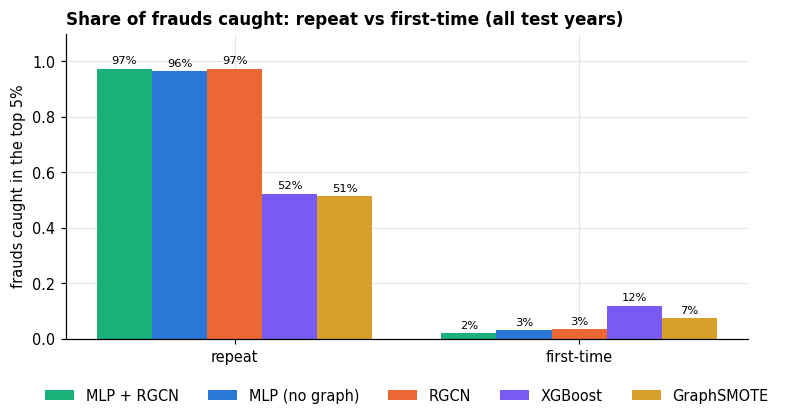

,MLP + RGCN,MLP (no graph),RGCN,XGBoost,GraphSMOTE
repeat,509 / 523,504 / 523,509 / 523,273 / 523,268 / 523
first-time,4 / 204,6 / 204,7 / 204,24 / 204,15 / 204


MLP + RGCN by year:


caught            frauds        catch_rate       
fraud_type first-time repeat first-time repeat first-time repeat
Year                                                            
2019                0    144         56    158      0.000  0.911
2020                0    131         76    131      0.000  1.000
2021                1    136         47    136      0.021  1.000
2022                3     98         25     98      0.120  1.000

In [39]:
catch_rate = pd.DataFrame({c: [(f & REPEAT).sum() / REPEAT.sum(), (f & FIRST_TIME).sum() / FIRST_TIME.sum()]
                           for c, f in FLAGS.items()}, index=["repeat", "first-time"])
catch_counts = pd.DataFrame({NAMES[c]: [f"{(f & REPEAT).sum()} / {REPEAT.sum()}", f"{(f & FIRST_TIME).sum()} / {FIRST_TIME.sum()}"]
                             for c, f in FLAGS.items()}, index=["repeat", "first-time"])

fig, ax = plt.subplots(figsize=(8, 3.6))
grouped_bars(ax, catch_rate, MODELS)
ax.set(ylabel="frauds caught in the top 5%", ylim=(0, 1.1), title="Share of frauds caught: repeat vs first-time (all test years)")
ax.legend(ncol=len(MODELS), loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

display(catch_counts)
print("MLP + RGCN by year:")
(wide[FRAUD].groupby(["Year", "fraud_type"])["flagged"].agg(caught="sum", frauds="size", catch_rate="mean")
 .round(3).unstack("fraud_type"))

## Repeat fraud

### Past offenders: model order vs random order

In [40]:
# Companies that were a fraud last year: how many reviews does the model's ranking save, compared with
# reviewing them in random order, to catch a given share of repeat frauds?
cand = wide[wide["fraud_last_year"] == 1]
per_year = cand.groupby("Year").agg(past_offenders=("nodeID", "size"), repeat_frauds=("Label", "sum"))
per_year["share who reoffend"] = (per_year["repeat_frauds"] / per_year["past_offenders"]).round(3)
display(per_year)


def reviews_needed(target):
    model, random = 0, 0.0
    for _, g in cand.groupby("Year"):
        labels_sorted = g.sort_values("ens_own", ascending=False)["Label"].to_numpy()
        k, n = labels_sorted.sum(), len(labels_sorted)
        need = int(np.ceil(target * k))
        model += int(np.argmax(labels_sorted.cumsum() >= need) + 1)
        random += need * (n + 1) / (k + 1)   # expected position of the need-th fraud in a random order
    return model, round(random)


rows = []
for target in [0.5, 0.8, 0.9, 0.95, 1.0]:
    model, random = reviews_needed(target)
    rows.append({"repeat frauds caught": f"{target:.0%}", "reviews (model order)": model,
                 "reviews (random order)": random, "reviews saved": random - model,
                 "saving": f"{1 - model / random:.0%}"})
pd.DataFrame(rows).set_index("repeat frauds caught")

,past_offenders,repeat_frauds,share who reoffend
Year,,,
2019,221,158,0.715
2020,210,131,0.624
2021,201,136,0.677
2022,173,98,0.566


,reviews (model order),reviews (random order),reviews saved,saving
repeat frauds caught,,,,
50%,365,402,37,9%
80%,622,645,23,4%
90%,705,726,21,3%
95%,765,768,3,0%
100%,803,803,0,0%


## First-time fraud: why it is missed

### Outcome profile

In [41]:
# Missed frauds (FN) vs caught frauds (TP): fraud history, next-year fraud, text and graph connections
profile = (wide.groupby("outcome")
           .agg(companies=("nodeID", "size"),
                fraud_last_year=("fraud_last_year", "mean"),
                fraud_next_year=("fraud_next_year", "mean"),
                has_text=("has_text", "mean"),
                isolated=("connections", lambda c: (c == 0).mean()),
                median_connections=("connections", "median"))
           .loc[["TP", "FN", "FP", "TN"]].round(3))
profile

,companies,fraud_last_year,fraud_next_year,has_text,isolated,median_connections
outcome,,,,,,
TP,513,0.992,0.624,0.975,0.000,27.0
FN,214,0.065,0.628,0.991,0.000,25.5
FP,388,0.686,0.067,1.000,0.000,26.0
TN,16870,0.001,0.010,0.980,0.001,24.0


### Missed frauds look like clean companies

In [ ]:
# Features before imputing and scaling, ranked across all test rows. Gap in average percentile:
# FN − TP = +0.20 means missed frauds sit 20 percentile points above caught ones; FN − TN near 0 means missed
# frauds look like clean companies. Descriptive only: with 1,000+ features, some gaps appear by chance.
# Caught frauds are almost all repeat and missed ones almost all first-time, so FN − TP mostly shows how repeat
# frauds differ from first-time ones; FN − TN is the robust comparison.
raw = pd.read_parquet(PROCESSED_DIR / "tabular_features").astype({"Year": int}).drop_duplicates(KEYS)
feature_cols = [c for c in raw.select_dtypes("number").columns
                if c not in KEYS + ["Label", "split"] and not c.endswith("_was_missing")]
rows = wide[KEYS + ["outcome"]].merge(raw[KEYS + feature_cols], on=KEYS, how="left")
mean_pct = rows[feature_cols].rank(pct=True).groupby(rows["outcome"].to_numpy()).mean()

gap_fn_tp = (mean_pct.loc["FN"] - mean_pct.loc["TP"]).dropna()
gap_fn_tn = mean_pct.loc["FN"] - mean_pct.loc["TN"]
top = gap_fn_tp.abs().sort_values(ascending=False).head(TOP_FEATURES).index
medians = rows.groupby("outcome")[list(top)].median().T
feature_table = pd.DataFrame({"median TP (caught)": medians["TP"], "median FN (missed)": medians["FN"],
                              "median TN (clean)": medians["TN"], "pct gap FN − TP": gap_fn_tp[top],
                              "pct gap FN − TN": gap_fn_tn[top]}).round(3)
TYPICAL_GAP_FN_TN = gap_fn_tn.abs().median()

fig, ax = plt.subplots(figsize=(8, 0.32 * TOP_FEATURES + 1))
gaps = gap_fn_tp[top][::-1]
ax.barh(gaps.index, gaps, color=np.where(gaps > 0, "#eb6834", "#2a78d6"))
ax.axvline(0, color="#52514e", linewidth=0.8)
ax.set(xlabel="missed − caught frauds, gap in average percentile",
       title="Features where missed frauds differ most from caught ones (caught frauds are mostly repeat)")
plt.show()

print(f"median |FN − TN| gap over all {len(feature_cols):,} features: {TYPICAL_GAP_FN_TN:.3f}")
feature_table

### Frauds missed by every model

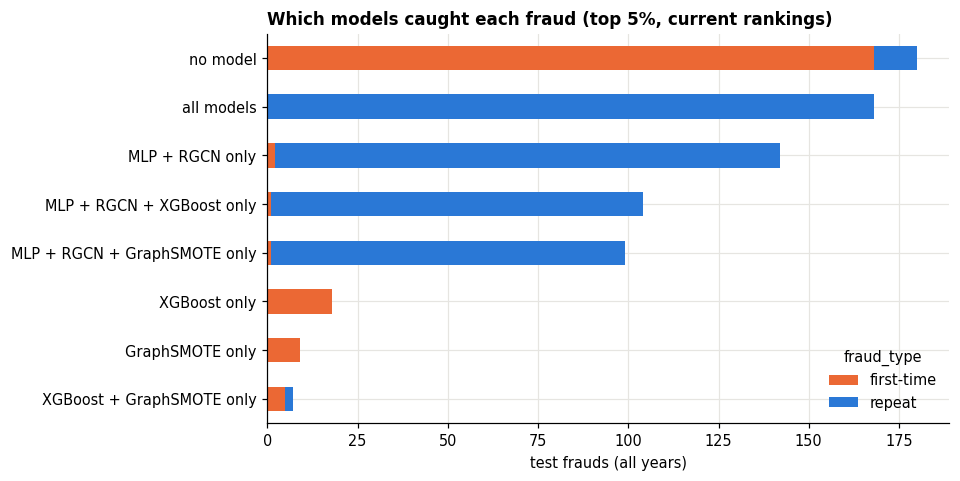

fraud_type,first-time,repeat,total
pattern,,,
no model,168,12,180
all models,0,168,168
MLP + RGCN only,2,140,142
MLP + RGCN + XGBoost only,1,103,104
MLP + RGCN + GraphSMOTE only,1,98,99
XGBoost only,18,0,18
GraphSMOTE only,9,0,9
XGBoost + GraphSMOTE only,5,2,7


First-time frauds, new companies only: caught by at least one model 76 of 204, missed by every model 128


,MLP + RGCN,XGBoost,GraphSMOTE
first-time caught,45,45,30


In [ ]:
# Current rankings: MLP + RGCN uses the history rule, which crowds out its first-time catches, so the first-time
# counts here overstate how many first-time frauds no model can find. See the check at the end of this cell.
COMPARE = [c for c in ["ens_score", "xgb", "gsmote"] if c in MODELS]   # one model per notebook
caught = pd.DataFrame({c: FLAGS[c][FRAUD] for c in COMPARE}).assign(fraud_type=wide.loc[FRAUD, "fraud_type"])


def pattern(row):
    hit = [NAMES[c] for c in COMPARE if row[c]]
    if len(hit) == len(COMPARE):
        return "all models"
    return "no model" if not hit else " + ".join(hit) + " only"


caught["pattern"] = caught.apply(pattern, axis=1)
overlap = caught.groupby(["pattern", "fraud_type"]).size().unstack("fraud_type", fill_value=0)
overlap["total"] = overlap.sum(axis=1)
overlap = overlap.sort_values("total")
MISSED_BY_ALL_FIRST_TIME = int(overlap.loc["no model", "first-time"]) if "no model" in overlap.index else 0

fig, ax = plt.subplots(figsize=(8, 0.45 * len(overlap) + 1))
overlap.drop(columns="total").plot.barh(stacked=True, ax=ax, color={"repeat": "#2a78d6", "first-time": "#eb6834"})
ax.set(xlabel="test frauds (all years)", ylabel="", title="Which models caught each fraud (top 5%, current rankings)")
plt.show()
display(overlap.iloc[::-1])

# First-time frauds only, with each model ranking companies without fraud last year (no history-rule crowding)
new_flags = {name: flag_top(f"{c}_new") for c, name in NEW_ONLY.items() if c != "ens_xgb"}
ft_caught = pd.DataFrame({name: f[FIRST_TIME] for name, f in new_flags.items()})
MISSED_BY_ALL_FIRST_TIME_NEW = int((~ft_caught.any(axis=1)).sum())
print(f"First-time frauds, new companies only: caught by at least one model {ft_caught.any(axis=1).sum()} "
      f"of {FIRST_TIME.sum()}, missed by every model {MISSED_BY_ALL_FIRST_TIME_NEW}")
ft_caught.sum().rename("first-time caught").to_frame().T

### Detection lag (from the history rule)

In [ ]:
# Frauds that continue into the next test year: was each caught this year, and what happened next year?
# This is produced by the rule, not learned: a fraud becomes a past offender the next year, and from 2020 the
# budget covers every past offender, so every fraud is flagged the year after. It shows how the system behaves.
nxt = (wide[KEYS + ["outcome"]].assign(Year=wide["Year"] - 1)
       .rename(columns={"outcome": "next_year_outcome"}))
lag = wide[FRAUD][KEYS + ["outcome", "fraud_type"]].merge(nxt, on=KEYS)   # frauds with a test-year row next year
NEXT = {"TP": "fraud, caught", "FN": "fraud, missed", "FP": "clean, flagged (FP)", "TN": "clean, not flagged"}
lag_table = pd.crosstab(lag["outcome"].map({"TP": "caught this year", "FN": "missed this year"}),
                        lag["next_year_outcome"].map(NEXT), rownames=["this year"], colnames=["next year"])
lag_table = lag_table.reindex(columns=list(NEXT.values()), fill_value=0)

missed_then = lag[lag["outcome"] == "FN"]
LAG_CAUGHT_NEXT = (missed_then["next_year_outcome"] == "TP").sum() / max((missed_then["next_year_outcome"].isin(["TP", "FN"])).sum(), 1)
print(f"missed frauds that continued the next year and were caught then: {LAG_CAUGHT_NEXT:.0%}")
display(lag_table)
print("Examples: missed one year, flagged the next")
(missed_then[missed_then["next_year_outcome"].isin(["TP", "FP"])]
 .assign(next_year=lambda d: d["next_year_outcome"].map(NEXT))[KEYS + ["fraud_type", "next_year"]].head(10))

missed frauds that continued the next year and were caught then: 100%


next year,"fraud, caught","fraud, missed","clean, flagged (FP)","clean, not flagged"
this year,,,,
caught this year,247,0,149,0
missed this year,118,0,70,0


Examples: missed one year, flagged the next


,nodeID,Year,fraud_type,next_year
0,L000004,2019,first-time,"fraud, caught"
10,L000632,2019,repeat,"fraud, caught"
12,L000676,2019,first-time,"fraud, caught"
13,L000752,2019,first-time,"clean, flagged (FP)"
14,L000782,2019,repeat,"fraud, caught"
15,L000802,2019,first-time,"clean, flagged (FP)"
18,L000851,2019,first-time,"clean, flagged (FP)"
22,L002071,2019,first-time,"clean, flagged (FP)"
31,L002134,2019,first-time,"clean, flagged (FP)"
35,L002175,2019,repeat,"clean, flagged (FP)"


## False positives

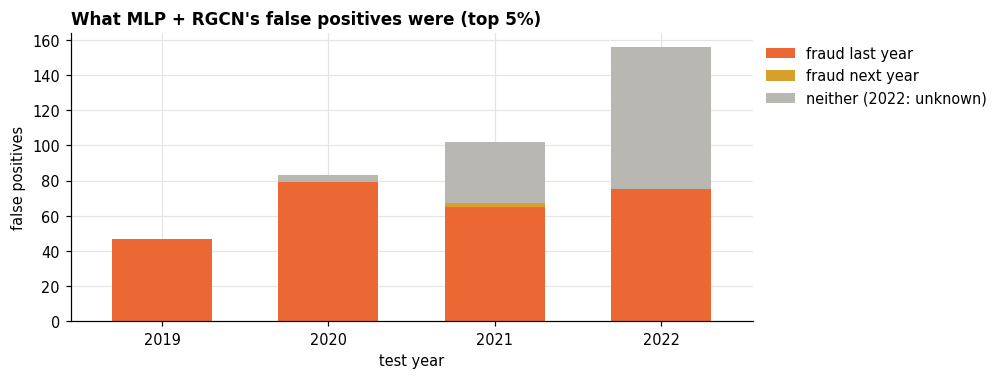

,flagged,frauds,FP,min_possible_FP,FP_fraud_last_year
Year,,,,,
2019,191,214,47,0,1.000
2020,214,207,83,7,0.952
2021,239,183,102,56,0.637
2022,257,123,156,134,0.481


In [ ]:
# min_possible_FP: flagging more companies than there are frauds forces some false positives.
# 2022 has no next-year labels, so its false positives can't show as "fraud next year".
main_year = wide.groupby("Year")
fp = wide[wide["outcome"] == "FP"]
fp_summary = pd.DataFrame({"flagged": main_year["flagged"].sum(),
                           "frauds": main_year["Label"].sum(),
                           "FP": fp.groupby("Year").size(),
                           "min_possible_FP": (main_year["flagged"].sum() - main_year["Label"].sum()).clip(lower=0),
                           "FP_fraud_last_year": fp.groupby("Year")["fraud_last_year"].mean()}).fillna({"FP": 0}).round(3)

fp_kind = np.select([fp["fraud_last_year"] == 1, fp["fraud_next_year"] == 1], ["fraud last year", "fraud next year"], "neither (2022: unknown)")
fp_mix = pd.crosstab(fp["Year"], fp_kind).reindex(columns=["fraud last year", "fraud next year", "neither (2022: unknown)"], fill_value=0)

fig, ax = plt.subplots(figsize=(8, 3.4))
fp_mix.plot.bar(stacked=True, ax=ax, color=["#eb6834", "#d6a02a", "#b8b7b1"], rot=0, width=0.6)
ax.set(xlabel="test year", ylabel="false positives", title="What MLP + RGCN's false positives were (top 5%)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()
fp_summary

## Ranking strategies

### Rules at the 5% budget

In [ ]:
# Same saved scores, ranked differently. "New companies only" gives the whole budget to companies with no fraud
# last year; for MLP + RGCN that uses model.ipynb's first-time model.
RULES = {"No model: last year's frauds first, rest random": flag_top("history"),
         "MLP + RGCN, current rule": FLAGS["ens_score"],
         "XGBoost, all companies": FLAGS["xgb"]}
RULES.update({f"{name}, new companies only": flag_top(f"{c}_new") for c, name in NEW_ONLY.items()})
rules_table = pd.DataFrame([summarise(f) for f in RULES.values()], index=list(RULES))
rules_table

,frauds caught,first-time caught,repeat caught,false positives,precision
"No model: last year's frauds first, rest random",503,0,503,398,0.558
"MLP + RGCN, current rule",513,4,509,388,0.569
"XGBoost, all companies",297,24,273,604,0.330
"MLP + RGCN, new companies only",45,45,0,856,0.050
"XGBoost, new companies only",45,45,0,856,0.050
"GraphSMOTE, new companies only",30,30,0,871,0.033
"MLP + RGCN and XGBoost (average rank), new companies only",50,50,0,851,0.055


### Splitting the budget

check: reserving all 5% reproduces the current rule: True


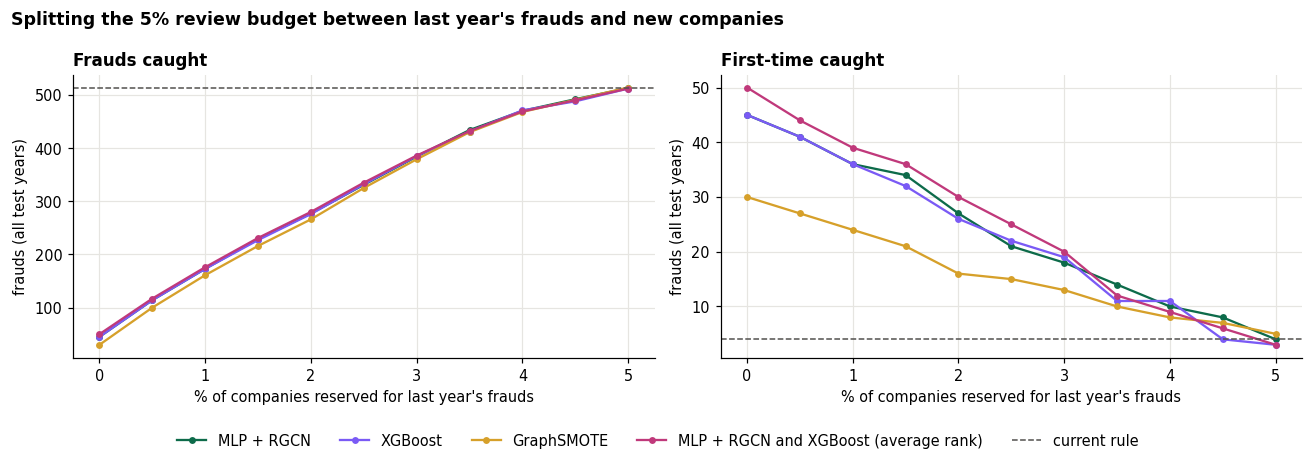

first-time caught             \
new companies ranked by        GraphSMOTE MLP + RGCN   
reserve                                                
0.000                                  30         45   
0.005                                  27         41   
0.010                                  24         36   
0.015                                  21         34   
0.020                                  16         27   
0.025                                  15         21   
0.030                                  13         18   
0.035                                  10         14   
0.040                                   8         10   
0.045                                   7          8   
0.050                                   5          4   

                                                                       \
new companies ranked by MLP + RGCN and XGBoost (average rank) XGBoost   
reserve                                                                 
0.000                                                      50      45   
0.005                                                      44      41   
0.010                                                      39      36   
0.015                                                      36      32   
0.020                                                      30      26   
0.025                                                      25      22   
0.030                                                      20      19   
0.035                                                      12      11   
0.040                                                       9      11   
0.045                                                       6       4   
0.050                                                       3       3   

                        frauds caught             \
new companies ranked by    GraphSMOTE MLP + RGCN   
reserve                                            
0.000                              30         45   
0.005                             100        114   
0.010                             161        173   
0.015                             216        229   
0.020                             266        277   
0.025                             325        331   
0.030                             379        384   
0.035                             430        434   
0.040                             468        470   
0.045                             491        492   
0.050                             514        513   

                                                                       
new companies ranked by MLP + RGCN and XGBoost (average rank) XGBoost  
reserve                                                                
0.000                                                      50      45  
0.005                                                     117     114  
0.010                                                     176     173  
0.015                                                     231     227  
0.020                                                     280     276  
0.025                                                     335     332  
0.030                                                     386     385  
0.035                                                     432     431  
0.040                                                     469     471  
0.045                                                     490     488  
0.050                                                     512     512

In [ ]:
sweep = pd.DataFrame([{"reserve": r, "new companies ranked by": name, **summarise(split_budget(r, c))}
                      for c, name in NEW_ONLY.items() for r in RESERVES])
current = rules_table.loc["MLP + RGCN, current rule"]
check = sweep.query("reserve == @FLAG_SHARE and `new companies ranked by` == 'MLP + RGCN'").iloc[0]
print(f"check: reserving all {FLAG_SHARE:.0%} reproduces the current rule: "
      f"{check['frauds caught'] == current['frauds caught'] and check['first-time caught'] == current['first-time caught']}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric in zip(axes, ["frauds caught", "first-time caught"]):
    for c, name in NEW_ONLY.items():
        line = sweep[sweep["new companies ranked by"] == name]
        ax.plot(line["reserve"] * 100, line[metric], marker="o", markersize=3.5, color=COLORS[f"{c}_new"], label=name)
    ax.axhline(current[metric], color="#52514e", linestyle="--", linewidth=1, label="current rule")
    ax.set(title=metric.capitalize(), xlabel="% of companies reserved for last year's frauds", ylabel="frauds (all test years)")
fig.suptitle(f"Splitting the {FLAG_SHARE:.0%} review budget between last year's frauds and new companies",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=len(NEW_ONLY) + 1)
plt.show()

sweep.pivot_table(index="reserve", columns="new companies ranked by", values=["frauds caught", "first-time caught"]).astype(int)

### Review budget for first-time frauds

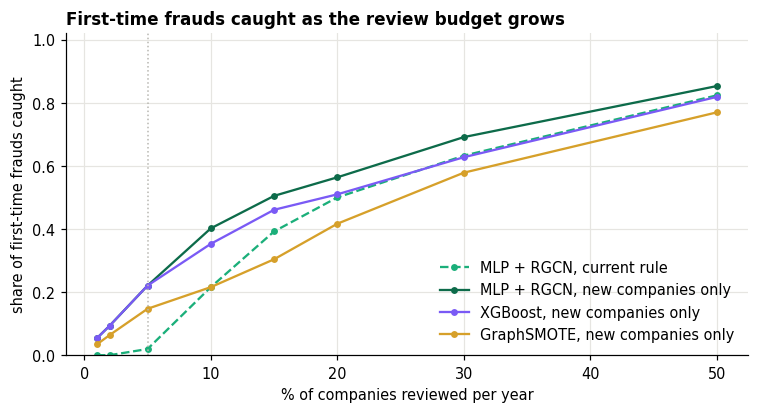

Share of companies to review per year to catch 25 / 50 / 75% of first-time frauds


,catch 25%,catch 50%,catch 75%
"MLP + RGCN, current rule",10.5%,19.9%,41.8%
"MLP + RGCN, new companies only",6.1%,14.7%,37.9%
"XGBoost, new companies only",5.9%,18.9%,40.4%
"GraphSMOTE, new companies only",11.7%,25.3%,49.0%


In [ ]:
# How much of each year's companies must be reviewed to catch first-time frauds, ranking new companies only
BUDGET_RANKINGS = {"ens_score": "MLP + RGCN, current rule", **{f"{c}_new": f"{name}, new companies only"
                                                              for c, name in NEW_ONLY.items() if c != "ens_xgb"}}
curve = pd.DataFrame({name: [(flag_top(c, b) & FIRST_TIME).sum() / FIRST_TIME.sum() for b in BUDGETS]
                      for c, name in BUDGET_RANKINGS.items()}, index=BUDGETS)
needed = pd.DataFrame({name: rank_pct(c)[FIRST_TIME].quantile([0.25, 0.50, 0.75]).to_numpy()
                       for c, name in BUDGET_RANKINGS.items()}, index=["catch 25%", "catch 50%", "catch 75%"]).T

fig, ax = plt.subplots(figsize=(8, 3.8))
for c, name in BUDGET_RANKINGS.items():
    ax.plot(curve.index * 100, curve[name], marker="o", markersize=3.5, color=COLORS[c], label=name,
            linestyle="--" if c == "ens_score" else "-")
ax.axvline(FLAG_SHARE * 100, color="#b8b7b1", linestyle=":", linewidth=1)
ax.set(xlabel="% of companies reviewed per year", ylabel="share of first-time frauds caught", ylim=(0, 1.02),
       title="First-time frauds caught as the review budget grows")
ax.legend(loc="lower right")
plt.show()

print("Share of companies to review per year to catch 25 / 50 / 75% of first-time frauds")
(needed * 100).round(1).astype(str) + "%"